In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.interpolate import UnivariateSpline

In [2]:
# SYSTEM DATA
systems = {
    "N=10": {
        "N_total": 10,
        "L"      : 8.03e-6,
        "color"  : "royalblue",
        "marker" : "^",
        "Np"     : np.array([1, 2, 3, 4, 5, 6, 7, 8, 9]),
        "mean"   : np.array([1.599, 1.965, 1.220, 1.456, 1.225,
                             1.010, 1.120, 1.222, 1.549]),
        "SEM"    : np.array([0.2820, 0.3442, 0.2193, 0.2130, 0.2699,
                             0.1254, 0.2811, 0.2363, 0.3257]),
        # Linear extrapolation: use first two points (near-ergodic baseline)
        "extrap_idx": [0, 1],
    },
    "N=30"  : {
        "N_total" : 30,
        "L"       : 13.9e-6, # Calculated to maintain area fraction consistency
        "color"   : "forestgreen",
        "marker"  : "D",
        "Np"      : np.array([1, 2, 3, 6, 9, 12, 15, 18, 21, 24, 27, 29]),
        "mean"    : np.array([1.852, 1.719, 1.244, 1.137, 0.9049, 0.7512, 
                              0.9852, 0.9050, 0.9796, 1.006, 1.136, 1.451]),
        "SEM"     : np.array([0.3017, 0.2682, 0.2097, 0.1122, 0.07465, 0.1038, 
                              0.1080, 0.1410, 0.1345, 0.1630, 0.1197, 0.1746]),
        "extrap_idx": [0, 2],
    },
    "N=50": {
        "N_total": 50,
        "L"      : 17.96e-6,
        "color"  : "darkorange",
        "marker" : "s",
        "Np"     : np.array([1, 2, 3, 4, 5, 10, 15, 20, 25, 30, 35, 40, 45, 48]),
        "mean"   : np.array([1.709, 1.244, 0.8070, 1.503, 1.205, 1.074,
                             0.8225, 0.8020, 0.8009, 0.7524, 0.8006,
                             0.8453, 1.0280, 0.9224]),
        "SEM"    : np.array([0.2002, 0.2175, 0.1036, 0.2028, 0.2066, 0.1344,
                             0.07676, 0.05881, 0.07846, 0.08448, 0.09008,
                             0.1006, 0.1476, 0.1900]),
        "extrap_idx": [0, 1],
    },
    "N=70" : {
        "N_total" : 70,
        "L"       : 21.26e-6,
        "color"   : "purple",
        "marker"  : "P",
        "Np"      : np.array([1, 2, 3, 4, 5, 6, 7, 14, 21, 28, 35, 42, 49, 56, 63, 67, 69]),
        "mean"    : np.array([1.433, 0.9578, 1.057, 1.010, 1.088, 0.8567, 0.8717, 
                              0.6555, 0.6850, 0.6147, 0.6911, 0.5660, 0.6897, 0.6683, 
                              0.9215, 1.391, 2.315]),
        "SEM"     : np.array([0.2781, 0.09632, 0.1204, 0.1251, 0.1018, 0.1189, 
                              0.09718, 0.08669, 0.06691, 0.05421, 0.05385, 
                              0.05628, 0.06248, 0.07728, 0.05126, 0.1975, 0.2016]),
        "extrap_idx": [0, 1],
    },
    "N=100": {
        "N_total": 100,
        "L"      : 25.4e-6,
        "color"  : "crimson",
        "marker" : "o",
        "Np"     : np.array([1,2,3,4,5,6,7,8,10,20,30,40,
                             50,60,70,80,90,91,92,93,94,95,96,97,98,99]),
        "mean"   : np.array([1.145, 0.5743, 0.5940, 0.5727, 0.4906, 0.5174,
                             0.4570, 0.3685, 0.3485, 0.3244, 0.3814, 0.3427,
                             0.2975, 0.3247, 0.2806, 0.3775, 0.3835, 0.4553,
                             0.4169, 0.5379, 0.4048, 0.6903, 0.5712, 0.6524,
                             0.7594, 1.128]),
        "SEM"    : np.array([0.1168, 0.06974, 0.09745, 0.1121, 0.06939, 0.05720,
                             0.05287, 0.05406, 0.02456, 0.02126, 0.03377, 0.03826,
                             0.02303, 0.01853, 0.02140, 0.03272, 0.03263, 0.03505,
                             0.04165, 0.06027, 0.06855, 0.09844, 0.07819, 0.08662,
                             0.1213, 0.1320]),
        "extrap_idx": [0, 4],   # Np=1 to Np=5: clean sub-critical baseline
    },
    
    "N=200" : {
                "N_total" : 200,
                "L"       : 35.92e-6,
                "color"   : "brown",
                "marker"  : "+",
                "Np"      : np.array([2, 4, 6, 8, 10, 12 ,14, 16, 18, 20, 40, 60, 80, 100, 120, 160, 180, 182, 184, 186, 188, 190, 192, 194, 196, 198]),
                "mean"    : np.array([1.097, 1.075, 0.8053, 0.7522, 0.8476,
                                        0.6749, 0.7527, 0.6687, 0.6663, 0.6757, 
                                        0.5463, 0.5612, 0.5050,  0.4830, 0.4867, 
                                        0.5216, 0.6966, 0.6885, 0.6779, 0.7035, 
                                        0.7453, 0.9456, 0.7788, 1.149, 1.196, 1.629]),
                "SEM"     : np.array([0.1385, 0.1485, 0.1008, 0.1045, 0.1030,
                                        0.09131, 0.07753, 0.03816, 0.05853, 0.06184, 
                                        0.03837, 0.02732, 0.02876, 0.02390, 0.04684, 
                                        0.05216 , 0.06966, 0.08016, 0.04862, 
                                        0.08801, 0.06016, 0.08549, 0.06112, 
                                        0.1328, 0.1788, 0.2752]),
                "extrap_idx": [0, 8],
            },
                
}

In [3]:
n_traj   = 10
np.random.seed(42)

# SHARED UTILITIES
d_probe = 2.0e-6
d_meth  = 1.0e-6
A_p     = np.pi * (d_probe / 2)**2
A_m     = np.pi * (d_meth  / 2)**2

In [4]:
def np_to_phi(n, N_total, L):
    """Area fraction for probe number n in a system with N_total and box side L."""
    n_f   = N_total - n
    A_box = L**2
    return (n * A_p + n_f * A_m) / A_box

def make_violin_data(mean_arr, SEM_arr, n_traj=10, n_synthetic=300):
    """
    Generate synthetic detection time distributions for violin plotting.
    Uses SD = SEM * sqrt(n_traj) as the spread — physically correct
    representation of run-to-run variability.
    Samples are clipped to positive values only.
    """
    std_arr = SEM_arr * np.sqrt(n_traj)
    data    = []
    for m, s in zip(mean_arr, std_arr):
        dist = np.random.normal(m, s, n_synthetic)
        data.append(dist[dist > 0])
    return data

def ergodic_extrapolation(Np_arr, EP_arr, idx_start, idx_end):
    """
    Two-point linear extrapolation through the near-ergodic (sub-critical)
    baseline, extended across the full Np range.
    idx_start, idx_end: indices into Np_arr/EP_arr defining the baseline segment.
    Returns x_line, y_line arrays for plotting.
    """
    x0, x1 = Np_arr[idx_start], Np_arr[idx_end]
    y0, y1 = EP_arr[idx_start], EP_arr[idx_end]
    slope   = (y1 - y0) / (x1 - x0)
    x_line  = np.array([Np_arr[0], Np_arr[-1]])
    y_line  = y0 + slope * (x_line - x0)
    return x_line, y_line

def find_ergodic_breakdown(Np_arr, EP_arr, EP_err_arr, x_ext, y_ext,
                            n_consecutive=2, sigma_mult=1.0):
    """
    Find Np_crit: the first probe count where the Ergodic Product genuinely
    takes off above the sub-critical linear extrapolation, using error bars
    so points that are still statistically consistent with the ergodic
    baseline aren't flagged.

    A point counts as "departed" only if its LOWER error bound
    (EP - sigma_mult*EP_err) is still above the extrapolation line at that
    Np -- i.e. even in the most conservative case, it's above the line.
    Requires `n_consecutive` such points in a row so a single noisy point
    doesn't trigger a false crossover.

    Returns Np_crit (float), or None if the system never clearly departs.
    """
    slope = (y_ext[-1] - y_ext[0]) / (x_ext[-1] - x_ext[0])
    x0, y0 = x_ext[0], y_ext[0]
    line_vals = y0 + slope * (Np_arr - x0)

    lower_bound = EP_arr - sigma_mult * EP_err_arr
    exceeds = lower_bound > line_vals

    for i in range(len(Np_arr) - n_consecutive + 1):
        if np.all(exceeds[i:i + n_consecutive]):
            return Np_arr[i]
    return None

In [5]:
# PRE-PROCESS
for name, sys in systems.items():
    Np_arr  = sys["Np"]
    mean    = sys["mean"]
    SEM_arr = sys["SEM"]
    std_arr = SEM_arr * np.sqrt(n_traj)
    N_total = sys["N_total"]
    L       = sys["L"]

    EP      = Np_arr * mean
    EP_err  = Np_arr * SEM_arr         # propagated SEM on ergodic product
    phi_arr = np.array([np_to_phi(n, N_total, L) for n in Np_arr])

    # Ergodic product extrapolation
    i0, i1    = sys["extrap_idx"]
    x_ext, y_ext = ergodic_extrapolation(Np_arr, EP, i0, i1)

    # Spline on ergodic product for visual guide
    Np_dense    = np.linspace(Np_arr.min(), Np_arr.max(), 500)
    weights_ep  = 1.0 / (EP_err + 1e-6)
    k_order     = min(4, len(Np_arr) - 1)
    spline_ep   = UnivariateSpline(Np_arr, EP, w=weights_ep,
                                   k=k_order, s=len(Np_arr) * 1.5)
    EP_spline   = spline_ep(Np_dense)

    # Ergodic breakdown point = minimum of the spline (onset of crowding-limited regime)
    Np_crit = find_ergodic_breakdown(Np_arr, EP, EP_err, x_ext, y_ext, n_consecutive = 2, sigma_mult = 1.0)
    phi_dense   = np.array([np_to_phi(n, N_total, L) for n in Np_dense])

    # Violin data
    violin_data = make_violin_data(mean, SEM_arr, n_traj=n_traj)

    sys.update({
        "std"       : std_arr,
        "EP"        : EP,
        "EP_err"    : EP_err,
        "phi_arr"   : phi_arr,
        "Np_dense"  : Np_dense,
        "phi_dense" : phi_dense,
        "EP_spline" : EP_spline,
        "x_ext"     : x_ext,
        "y_ext"     : y_ext,
        "violin"    : violin_data,
        "crit"      : Np_crit,
    })

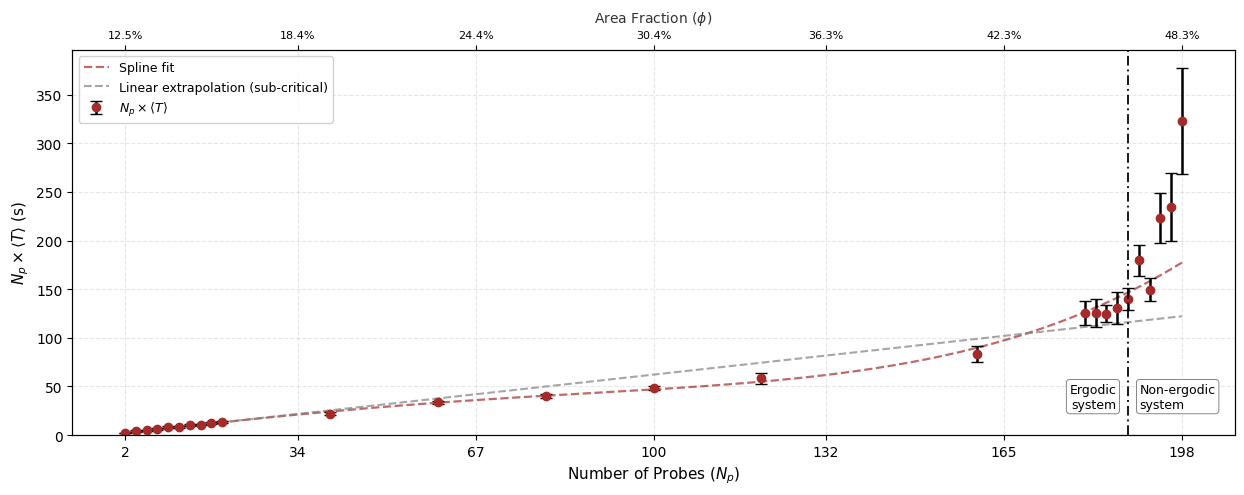

In [6]:
# Change this key to plot any system size (e.g., "N=10", "N=100", "N=200")
TARGET_SYSTEM = "N=200"

# Retrieve system dictionary
sys = systems[TARGET_SYSTEM]
name = TARGET_SYSTEM

Np_arr  = sys["Np"]
EP      = sys["EP"]
EP_err  = sys["EP_err"]
N_total = sys["N_total"]
L       = sys["L"]
color   = sys["color"]
Np_crit = sys["crit"]
# Extract range & compute relative 5% padding so it scales dynamically for any system
np_min, np_max = Np_arr.min(), Np_arr.max()
x_range = np_max - np_min
pad = x_range * 0.05 if x_range > 0 else 0.5

# Create single-panel figure
fig, ax = plt.subplots(figsize=(15, 5))

# Data points with error bars
ax.errorbar(
    Np_arr, EP, yerr=EP_err,
    fmt='o', color=color, ecolor='black',
    capsize=4, markersize=6, linewidth=1.8, zorder=3,
    label=r'$N_p \times \langle T \rangle$'
)

# Spline fit
ax.plot(
    sys["Np_dense"], sys["EP_spline"],
    color=color, linewidth=1.6, linestyle='--', alpha=0.7,
    label='Spline fit')

# Sub-critical linear extrapolation
ax.plot(
    sys["x_ext"], sys["y_ext"],
    '--', color='gray', linewidth=1.5, alpha=0.7,
    label='Linear extrapolation (sub-critical)')

ax.set_ylabel(r'$N_p \times \langle T \rangle$ (s)', fontsize=11)
ax.set_xlabel("Number of Probes ($N_p$)", fontsize=11)


# ax.set_title(f'{name}: Ergodic Product Check', fontsize=12, fontweight='bold', pad=25)
ax.legend(fontsize=9, loc='upper left', framealpha=0.9)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(bottom=0)


Np_crit = sys["crit"]
x_lo, x_hi = ax.get_xlim()
x_span = x_hi - x_lo

if Np_crit is not None:
    ax.axvline(Np_crit, color='black', linestyle=(0, (5, 2, 1, 2)),
                   linewidth=1.4, alpha=0.9, zorder=5)

    trans = ax.get_xaxis_transform()  # x in data units, y in axes-fraction (0-1)
    label_style = dict(transform=trans, va='center', fontsize=9,
                            fontweight='medium', color='black', zorder=10,
                            bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                                      edgecolor='0.5', alpha=0.95, linewidth=0.7))
    offset = x_span * 0.010
    ax.text(Np_crit - offset, 0.1, "Ergodic\nsystem", ha='right', **label_style)
    ax.text(Np_crit + offset, 0.1, "Non-ergodic\nsystem", ha='left', **label_style)
else:
        # System never departs from the ergodic baseline within the tested range
        trans = ax.get_xaxis_transform()
        ax.text(0.5, 0.7, "Ergodic system", ha='center', va='center',
                transform=ax.transAxes, fontsize=9, fontweight='medium',
                color='black', zorder=10,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                          edgecolor='0.5', alpha=0.95, linewidth=0.7))
# Apply dynamic padding to x-limits
ax.set_xlim(np_min - pad, np_max + pad)

# ==========================================
# TOP SECONDARY AXIS: Area fraction (phi)
# ==========================================
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())

# Generate ticks starting EXACTLY at np_min and ending EXACTLY at np_max
num_ticks = min(7, len(np.unique(Np_arr)))
tick_Np = np.linspace(np_min, np_max, num_ticks).astype(int)
tick_Np = np.unique(tick_Np)

# Synchronize bottom and top ticks
ax.set_xticks(tick_Np)
ax_top.set_xticks(tick_Np)

ax_top.set_xticklabels(
    [f"{np_to_phi(n, N_total, L)*100:.1f}%" for n in tick_Np],
    fontsize=8
)
ax_top.set_xlabel(r"Area Fraction ($\phi$)", fontsize=10, color='black', alpha=0.8, labelpad=6)

# Save and display
clean_filename = name.replace("=", "_").replace(" ", "_")
# plt.savefig(f"ergodic_individual_{clean_filename}.jpg", dpi=300, bbox_inches='tight')
# plt.savefig(f"ergodic_individual_{clean_filename}.pdf", dpi=300, bbox_inches='tight')
# plt.show()



C:\Users\VENSER\AppData\Local\Temp\ipykernel_14820\3874410492.py:74: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


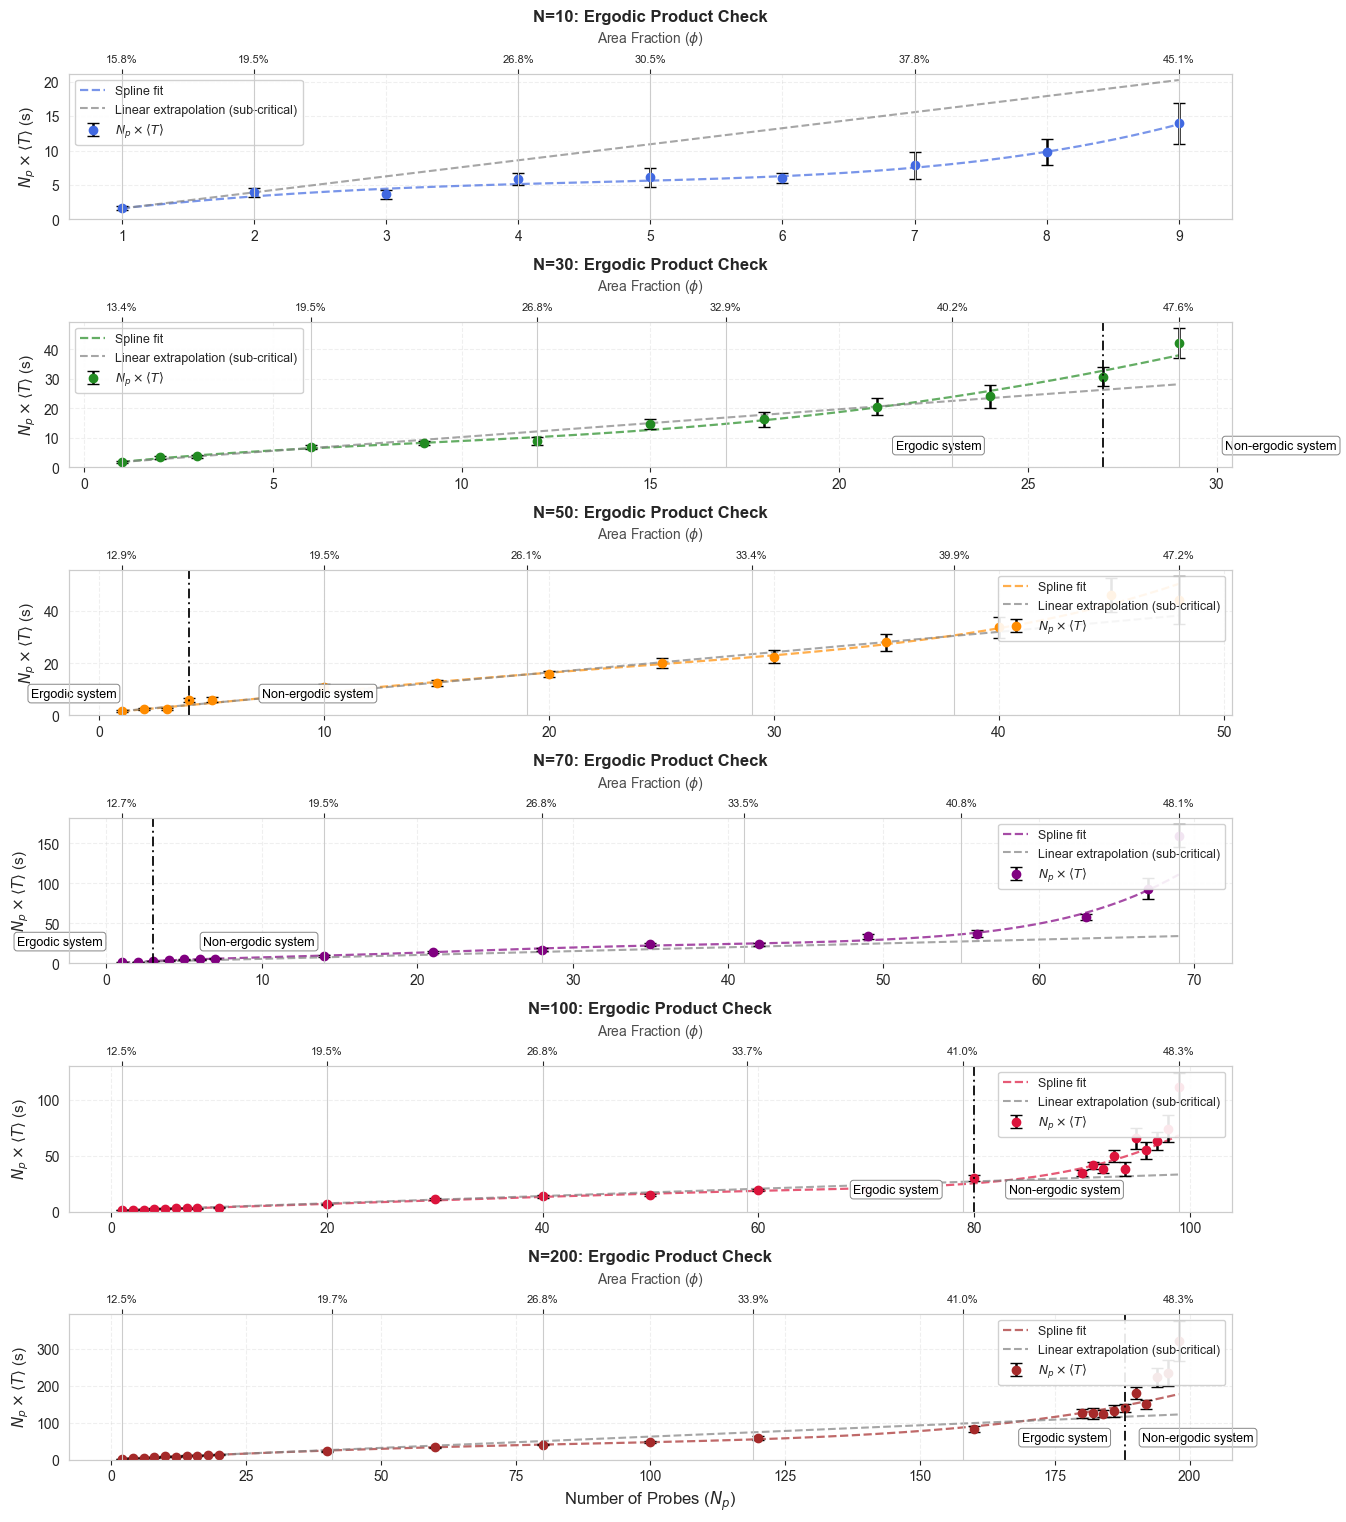

In [40]:
# FIGURE A — ERGODIC PRODUCT: individual panels (3 rows)
figA, axesA = plt.subplots(6, 1, figsize=(15, 18),
                            gridspec_kw={"hspace": 0.7})

for ax, (name, sys) in zip(axesA, systems.items()):
    Np_arr  = sys["Np"]
    EP      = sys["EP"]
    EP_err  = sys["EP_err"]
    N_total = sys["N_total"]
    L       = sys["L"]
    color   = sys["color"]

    # Data points with error bars
    ax.errorbar(
        Np_arr, EP, yerr=EP_err,
        fmt='o', color=color, ecolor='black',
        capsize=4, markersize=6, linewidth=1.8, zorder=3,
        label=r'$N_p \times \langle T \rangle$'
    )

    # Spline fit
    ax.plot(sys["Np_dense"], sys["EP_spline"],
            color=color, linewidth=1.6, linestyle='--', alpha=0.7,
            label='Spline fit')

    # Sub-critical linear extrapolation
    ax.plot(sys["x_ext"], sys["y_ext"],
            '--', color='gray', linewidth=1.5, alpha=0.7,
            label='Linear extrapolation (sub-critical)')

    ax.set_ylabel(r'$N_p \times \langle T \rangle$ (s)', fontsize=11)
    ax.set_title(f'{name}: Ergodic Product Check', fontsize=12, fontweight='bold')
    
    ax.grid(True, linestyle='--', alpha=0.3)
    ax.set_axisbelow(True)
    ax.set_ylim(bottom=0)
    
    if Np_crit is not None and (Np_crit - x_lo) < 0.5 * x_span:
        legend_loc = 'upper right'
    else:
        legend_loc = 'upper left'
    ax.legend(fontsize=9, loc=legend_loc, framealpha=0.9)
    Np_crit = sys['crit']
    if Np_crit is not None:
        ax.axvline(Np_crit, color='black', linestyle=(0, (5, 2, 1, 2)),
                   linewidth=1.4, alpha=0.9, zorder=5)

        trans = ax.get_xaxis_transform()  # x in data units, y in axes-fraction (0-1)
        label_style = dict(transform=trans, va='center', fontsize=9,
                            fontweight='medium', color='black', zorder=10,
                            bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                                      edgecolor='0.5', alpha=0.95, linewidth=0.7))
        offset = x_span * 0.015
        ax.text(Np_crit - offset, 0.15, "Ergodic system", ha='right', **label_style)
        ax.text(Np_crit + offset, 0.15, "Non-ergodic system", ha='left', **label_style)
        
    # Top axis: area fraction
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    tick_Np = np.unique(
        np.clip(np.linspace(Np_arr.min(), Np_arr.max(), 6).astype(int),
                Np_arr.min(), Np_arr.max())
    )
    ax_top.set_xticks(tick_Np)
    ax_top.set_xticklabels(
        [f"{np_to_phi(n, N_total, L)*100:.1f}%" for n in tick_Np],
        fontsize=8
    )
    ax_top.set_xlabel(r"Area Fraction ($\phi$)", fontsize=10,
                      color='black', alpha=0.7, labelpad=8)

axesA[-1].set_xlabel("Number of Probes ($N_p$)", fontsize=12)

plt.tight_layout()
# plt.savefig("FigA_ergodic_individual.jpg",dpi=300, bbox_inches='tight')
# plt.savefig("FigA_ergodic_individual.pdf",dpi=300, bbox_inches='tight')
# plt.show()

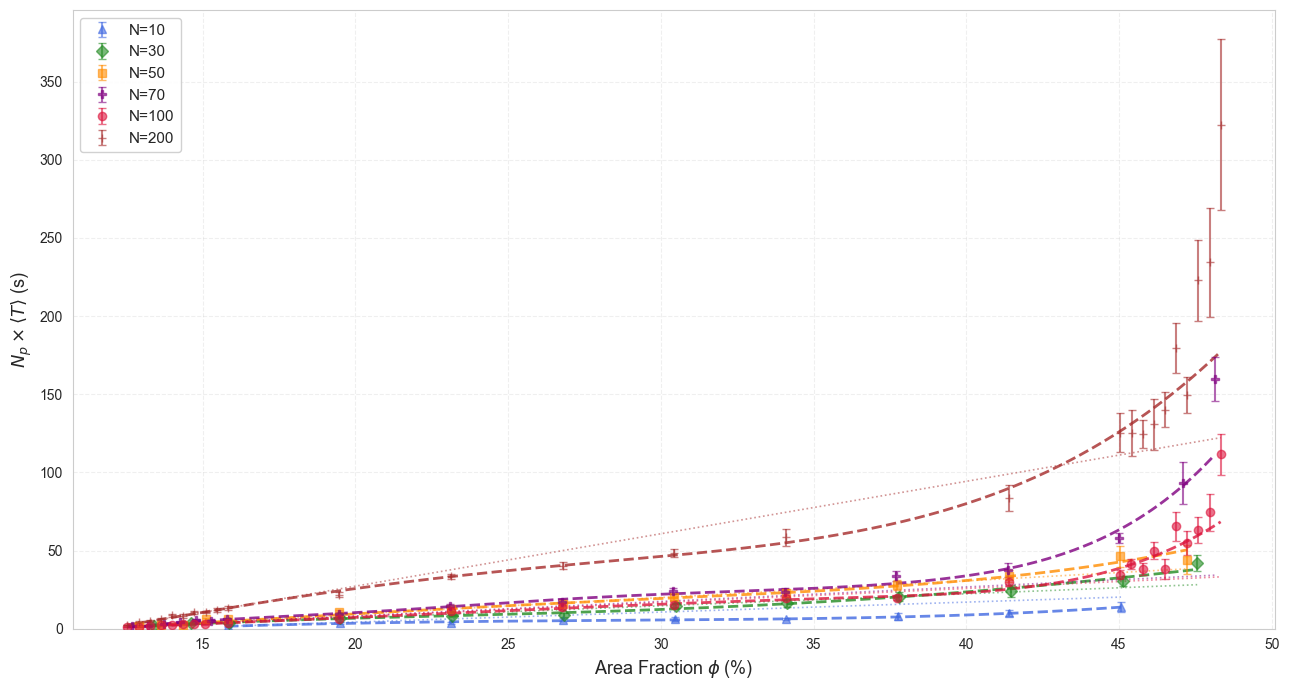

In [41]:
# FIGURE B — ERGODIC PRODUCT: overlay on phi axis
figB, ax_ov = plt.subplots(figsize=(13, 7))

for name, sys in systems.items():
    color  = sys["color"]
    marker = sys["marker"]

    ax_ov.errorbar(
        sys["phi_arr"] * 100, sys["EP"], yerr=sys["EP_err"],
        fmt=marker, color=color, ecolor=color, alpha=0.6,
        capsize=3, markersize=6, linewidth=1.5, zorder=3,
        label=f'{name}'
    )
    ax_ov.plot(sys["phi_dense"] * 100, sys["EP_spline"],
               color=color, linewidth=2, linestyle='--', alpha=0.8)

    # Extrapolation line in phi space
    phi_ext = np.array([np_to_phi(n, sys["N_total"], sys["L"]) * 100
                        for n in sys["x_ext"]])
    ax_ov.plot(phi_ext, sys["y_ext"],
               color=color, linewidth=1.2, linestyle=':', alpha=0.5)

ax_ov.set_xlabel(r"Area Fraction $\phi$ (%)", fontsize=13)
ax_ov.set_ylabel(r'$N_p \times \langle T \rangle$ (s)', fontsize=13)
# ax_ov.set_title("Ergodic Product Comparison across all system\n"r"(aligned by area fraction $\phi$; dotted = sub-critical extrapolation)",fontsize=13, fontweight='bold')
ax_ov.legend(fontsize=11, loc='upper left', framealpha=0.9)
ax_ov.grid(True, linestyle='--', alpha=0.3)
ax_ov.set_axisbelow(True)
ax_ov.set_ylim(bottom=0)

plt.tight_layout()
plt.savefig("FigB_ergodic_overlay.jpg", dpi=300, bbox_inches='tight')
# plt.savefig("FigB_ergodic_overlay.pdf", dpi=300, bbox_inches='tight')
plt.show()

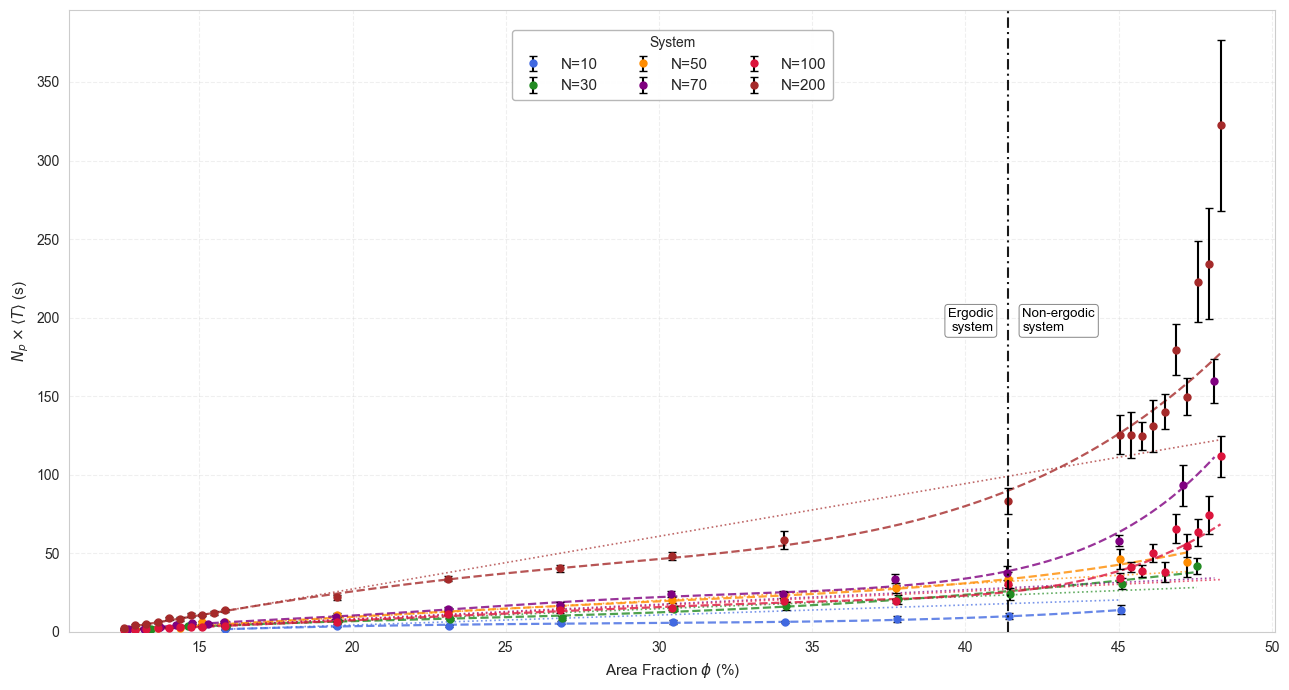

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Create single-panel figure
fig, ax = plt.subplots(figsize=(13, 7))

# Loop over systems to plot curves on the primary x-axis (phi)
for name, sys in systems.items():
    color = sys["color"]
    N_total = sys["N_total"]
    L = sys["L"]
    
    # Compute area fraction (%) for raw data x-values
    phi_arr = np_to_phi(sys["Np"], N_total, L) * 100
    phi_dense = np_to_phi(sys["Np_dense"], N_total, L) * 100
    
    # 1. Plot raw data points
    ax.errorbar(
        phi_arr, sys["EP"], yerr=sys["EP_err"],
        fmt='o', color=color, ecolor='black',
        capsize=3, markersize=5, linewidth=1.5, zorder=3,
        label=f'N={N_total}'
    )

    # 2. Plot spline fit
    ax.plot(
        phi_dense, sys["EP_spline"],
        color=color, linewidth=1.6, linestyle='--', alpha=0.8
    )
    
    # 3. Plot sub-critical linear extrapolation (if present)
    if "x_ext" in sys and "y_ext" in sys:
        phi_ext = np_to_phi(sys["x_ext"], N_total, L) * 100
        ax.plot(
            phi_ext, sys["y_ext"],
            ':', color=color, linewidth=1.2, alpha=0.7
        )

    # =========================================================
    # VERTICAL LINE & ERGODICITY BREAK (ONLY FOR N_total = 100)
    # =========================================================
    if N_total == 100:
        Np_crit = sys.get("crit")
        if Np_crit is not None:
            # Convert critical probe count to critical Area Fraction (%)
            phi_crit = np_to_phi(Np_crit, N_total, L) * 100
            
            # Draw vertical break line
            ax.axvline(
                phi_crit, color='black', linestyle=(0, (5, 2, 1, 2)),
                linewidth=1.5, alpha=0.9, zorder=5
            )

            # Translucent text labels positioned relative to vertical line
            trans = ax.get_xaxis_transform()
            label_style = dict(
                transform=trans, va='center', fontsize=9.5,
                fontweight='medium', color='black', zorder=10,
                bbox=dict(boxstyle='round,pad=0.25', facecolor='white',
                          edgecolor='0.5', alpha=0.95, linewidth=0.7)
            )
            
            # Horizontal offset relative to axis range
            x_lo, x_hi = ax.get_xlim()
            offset = (x_hi - x_lo) * 0.012 if (x_hi - x_lo) > 0 else 0.5

            ax.text(phi_crit - offset, 0.50, "Ergodic\nsystem", ha='right', **label_style)
            ax.text(phi_crit + offset, 0.50, "Non-ergodic\nsystem", ha='left', **label_style)

# Axis Labels and Styling
ax.set_ylabel(r'$N_p \times \langle T \rangle$ (s)', fontsize=11)
ax.set_xlabel(r"Area Fraction $\phi$ (%)", fontsize=11)
ax.grid(True, linestyle='--', alpha=0.3)
ax.set_axisbelow(True)
ax.set_ylim(bottom=0)

# ==========================================
# CENTERED 3x2 LEGEND (LARGER & CENTERED)
# ==========================================
ax.legend(
    title = 'System',
    fontsize=11,
    ncols=3,                      # Arranges 6 items into 3 columns x 2 rows
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.98),  # Positioned top-center to eliminate dead space
    framealpha=0.95,
    edgecolor='0.7'
)

plt.tight_layout()
plt.savefig("overlay_phi.jpg", dpi=300, bbox_inches='tight')
# plt.show()

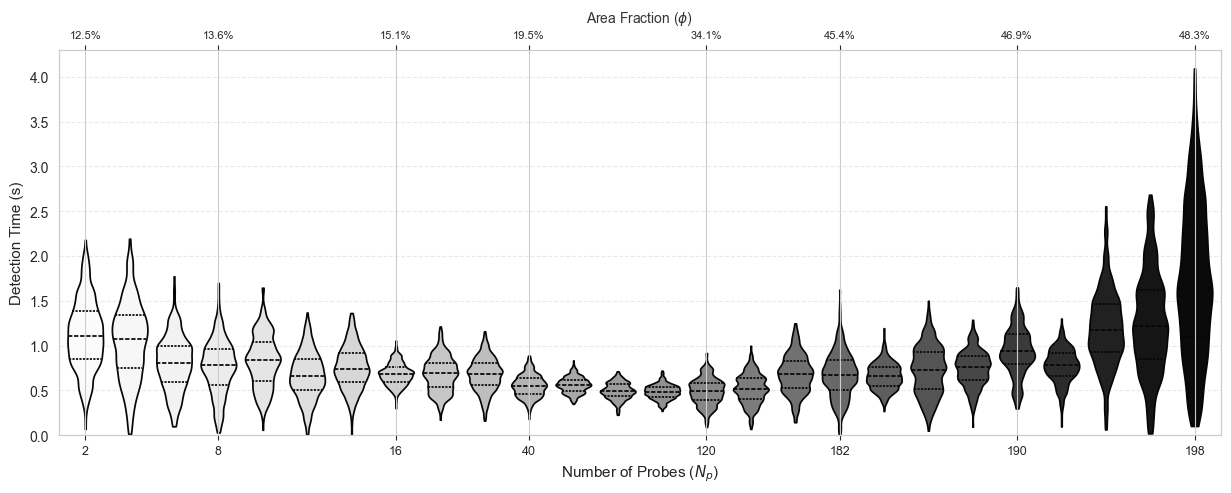

In [42]:
# Change this key to plot any system size (e.g., "N=10", "N=30", "N=100", "N=200")
TARGET_SYSTEM = "N=200"

palette_map = {
    "N=10" : "Blues",
    "N=30" : "Greens",
    "N=50" : "Oranges",
    "N=70" : "Purples",
    "N=100": "Reds",
    "N=200": "Grays"
}

# Retrieve system dictionary
sys = systems[TARGET_SYSTEM]
name = TARGET_SYSTEM

Np_arr  = sys["Np"]
N_total = sys["N_total"]
L       = sys["L"]

# Create single-panel figure
fig, ax = plt.subplots(figsize=(15, 5))

# Seaborn violin plot
sns.set_style("whitegrid")
sns.violinplot(
    data=sys["violin"],
    palette=palette_map.get(name, "Blues"),
    inner="quartile",
    cut=0,
    bw_adjust=0.6,
    ax=ax
)

ax.set_axisbelow(True)
ax.grid(True, axis='y', linestyle='--', alpha=0.4)
ax.set_ylabel("Detection Time (s)", fontsize=11)
ax.set_xlabel("Number of Probes ($N_p$)", fontsize=11)
# ax.set_title(f"{name}: Detection Time Distributions", fontsize=12, fontweight='bold', pad=25)
ax.set_ylim(bottom=0)

# AXIS TICK & AREA FRACTION ALIGNMENT
n_points = len(Np_arr)

# For smaller systems (<= 12 points), plot every single tick.
# For larger systems (> 12 points), pick up to 8 evenly spaced indices.
if n_points <= 12:
    indices = np.arange(n_points)
else:
    indices = np.linspace(0, n_points - 1, 8).astype(int)

# Set bottom x-ticks directly mapped to category positions
ax.set_xticks(indices)
ax.set_xticklabels([str(Np_arr[i]) for i in indices], rotation=0, fontsize=9)

# Apply dynamic side padding so edge violins aren't clipped by plot borders
ax.set_xlim(-0.6, n_points - 0.4)

# Top secondary axis for Area Fraction (phi)
ax_top = ax.twiny()
ax_top.set_xlim(ax.get_xlim())
ax_top.set_xticks(indices)

ax_top.set_xticklabels([f"{np_to_phi(Np_arr[i], N_total, L)*100:.1f}%" for i in indices],fontsize=8)
ax_top.set_xlabel(r"Area Fraction ($\phi$)", fontsize=10, color='black', alpha=0.8, labelpad=6)

# Save and display
clean_filename = name.replace("=", "_").replace(" ", "_")
# plt.savefig(f"violin_individual_{clean_filename}.jpg", dpi=300, bbox_inches='tight')
# plt.savefig(f"violin_individual_{clean_filename}.pdf", dpi=300, bbox_inches='tight')
# plt.show()

C:\Users\VENSER\AppData\Local\Temp\ipykernel_14820\3287427995.py:56: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


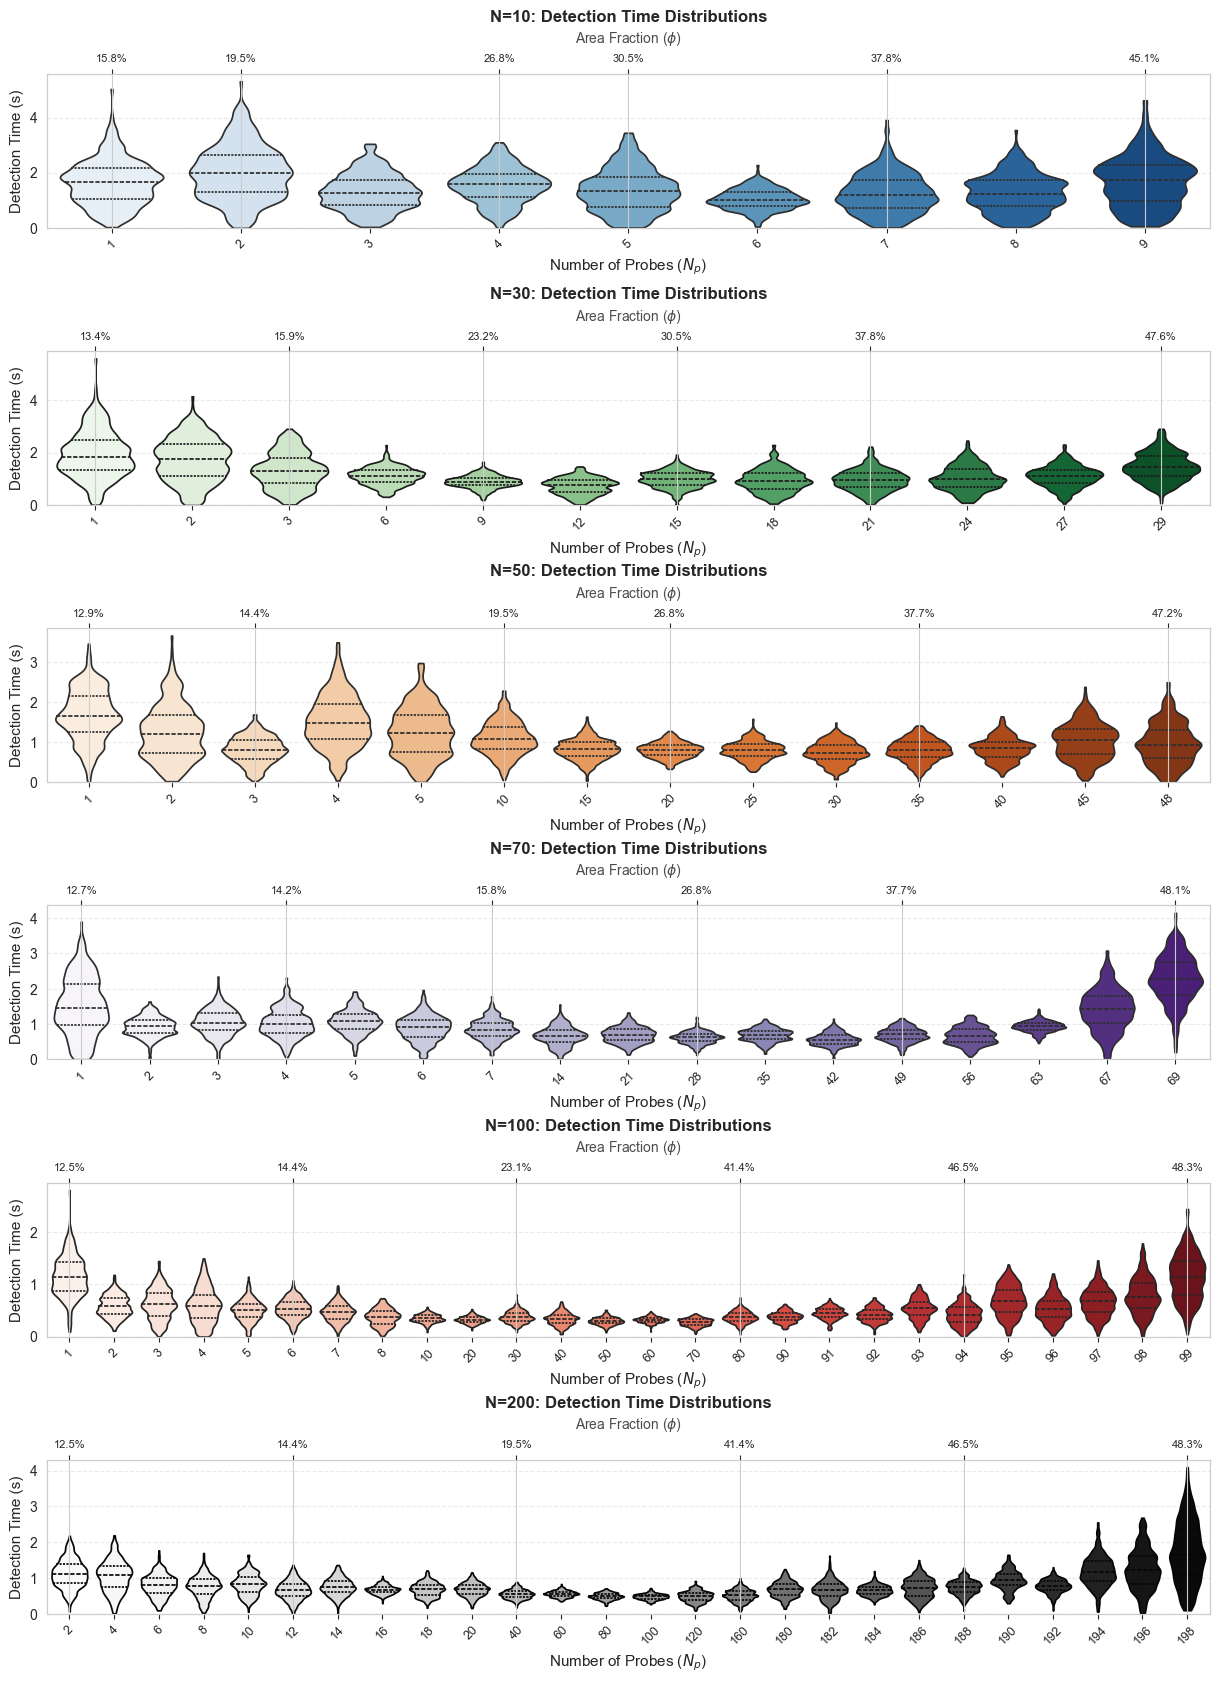

In [43]:
# FIGURE C — VIOLIN PLOTS: individual panels (3 rows)
# Note: distributions are synthetic, generated from mean ± SD
# (SD = SEM * sqrt(n_traj)) to approximate run-to-run spread.
# Replace violin_data with actual raw detection times if available.
palette_map = {
    "N=10" : "Blues",
    "N=30" : "Greens",
    "N=50" : "Oranges",
    "N=70" : "Purples",
    "N=100": "Reds",
    "N=200": "Grays"
}

figC, axesC = plt.subplots(6, 1, figsize=(15, 20),
                            gridspec_kw={"hspace": 0.8})

for ax, (name, sys) in zip(axesC, systems.items()):
    Np_arr  = sys["Np"]
    N_total = sys["N_total"]
    L       = sys["L"]
    labels  = [str(n) for n in Np_arr]

    sns.set_style("whitegrid")
    sns.violinplot(
        data=sys["violin"],
        palette=palette_map[name],
        inner="quartile",
        cut=0,
        bw_adjust=0.6,
        ax=ax
    )
    ax.set_axisbelow(True)
    ax.grid(True, axis='y', linestyle='--', alpha=0.4)
    ax.set_xticks(range(len(Np_arr)))
    ax.set_xticklabels(labels, rotation=45, fontsize=9)
    ax.set_xlabel("Number of Probes ($N_p$)", fontsize=11)
    ax.set_ylabel("Detection Time (s)", fontsize=11)
    ax.set_title(f"{name}: Detection Time Distributions",
                 fontsize=12, fontweight='bold')
    ax.set_ylim(bottom=0)

    # Top axis: area fraction
    ax_top = ax.twiny()
    ax_top.set_xlim(ax.get_xlim())
    # Show subset of ticks to avoid crowding
    n_show  = min(6, len(Np_arr))
    indices = np.linspace(0, len(Np_arr) - 1, n_show).astype(int)
    ax_top.set_xticks(indices)
    ax_top.set_xticklabels(
        [f"{np_to_phi(Np_arr[i], N_total, L)*100:.1f}%" for i in indices],
        fontsize=8
    )
    ax_top.set_xlabel(r"Area Fraction ($\phi$)", fontsize=10,
                      color='black', alpha=0.7, labelpad=8)
    
plt.tight_layout()
# plt.savefig("FigC_violin_individual.jpg",dpi=300, bbox_inches='tight')
# plt.savefig("FigC_violin_individual.pdf",dpi=300, bbox_inches='tight')
# plt.show()

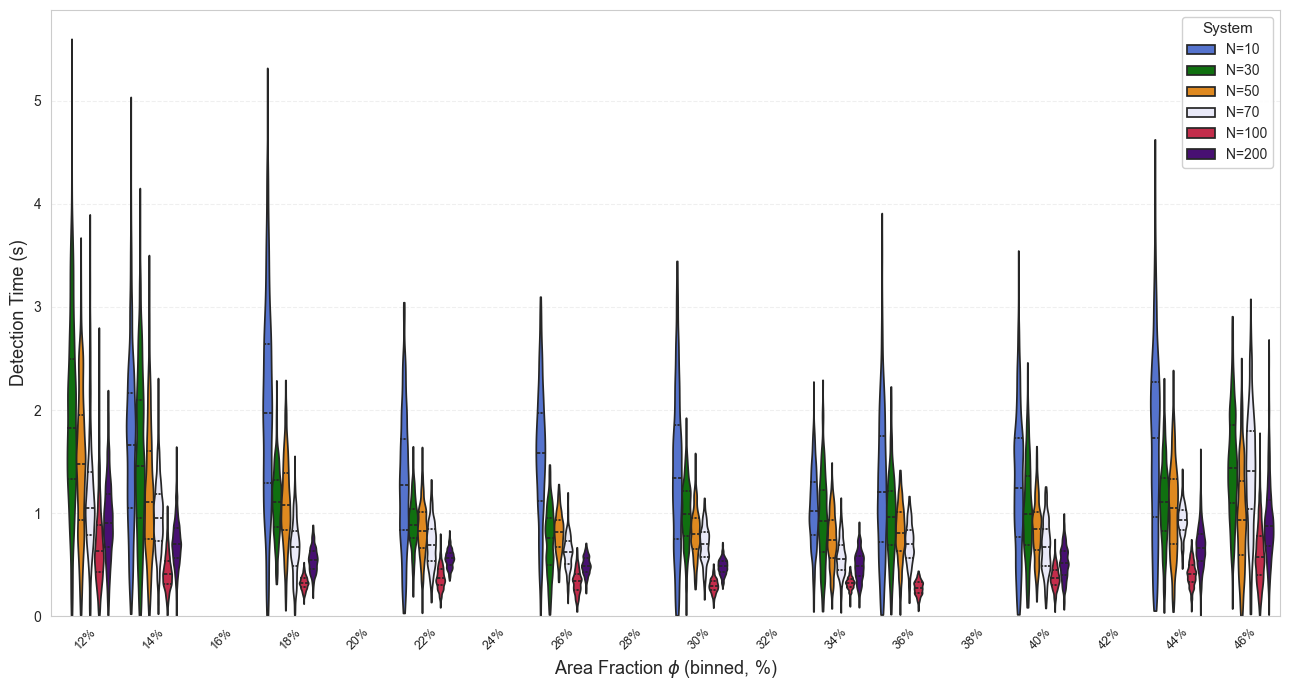

In [44]:
# FIGURE D — VIOLIN PLOTS: side-by-side overlay
# All three systems shown together on a shared phi axis.
# Since each system covers the same phi range, we align them
# by computing phi for each Np and placing violins at their
# phi position. We use a combined strip plot for this.
figD, ax_vov = plt.subplots(figsize=(13, 7))
sns.set_style("whitegrid")

# Build a combined dataset with phi labels for all systems
import pandas as pd

rows = []
for name, sys in systems.items():
    Np_arr  = sys["Np"]
    N_total = sys["N_total"]
    L       = sys["L"]
    for i, (n, dist) in enumerate(zip(Np_arr, sys["violin"])):
        phi_label = f"{np_to_phi(n, N_total, L)*100:.1f}%"
        for val in dist:
            rows.append({
                "System"       : name,
                "phi_label"    : phi_label,
                "phi_val"      : np_to_phi(n, N_total, L) * 100,
                "Detection Time": val,
            })

df = pd.DataFrame(rows)

# Bin phi into shared brackets for overlay comparison
phi_bins   = np.arange(12, 50, 2)
df["phi_bin"] = pd.cut(df["phi_val"], bins=phi_bins,
                        labels=[f"{b:.0f}%" for b in phi_bins[:-1]])
df = df.dropna(subset=["phi_bin"])

sns.violinplot(
    data=df,
    x="phi_bin", y="Detection Time",
    hue="System",
    palette={"N=10": "royalblue", "N=30": "Green", "N=50": "darkorange","N=70": "lavender", "N=100": "crimson", "N=200": "indigo"},
    inner="quartile",
    cut=0,
    bw_adjust=0.6,
    ax=ax_vov,
    dodge=True,
    density_norm="width"
)

ax_vov.set_xlabel(r"Area Fraction $\phi$ (binned, %)", fontsize=13)
ax_vov.set_ylabel("Detection Time (s)", fontsize=13)
# ax_vov.set_title("Detection Time Distributions across all systems\n"r"(grouped by shared area fraction $\phi$ bins)",fontsize=13, fontweight='bold')
ax_vov.legend(title="System", fontsize=10, title_fontsize=11,
              loc='upper right', framealpha=0.9)
ax_vov.grid(True, axis='y', linestyle='--', alpha=0.3)
ax_vov.set_axisbelow(True)
ax_vov.set_ylim(bottom=0)
plt.xticks(rotation=45, fontsize=9)

plt.tight_layout()
plt.savefig("FigD_violin_overlay.jpg",dpi=300, bbox_inches='tight')
# plt.savefig("FigD_violin_overlay.pdf",dpi=300, bbox_inches='tight')
plt.show()


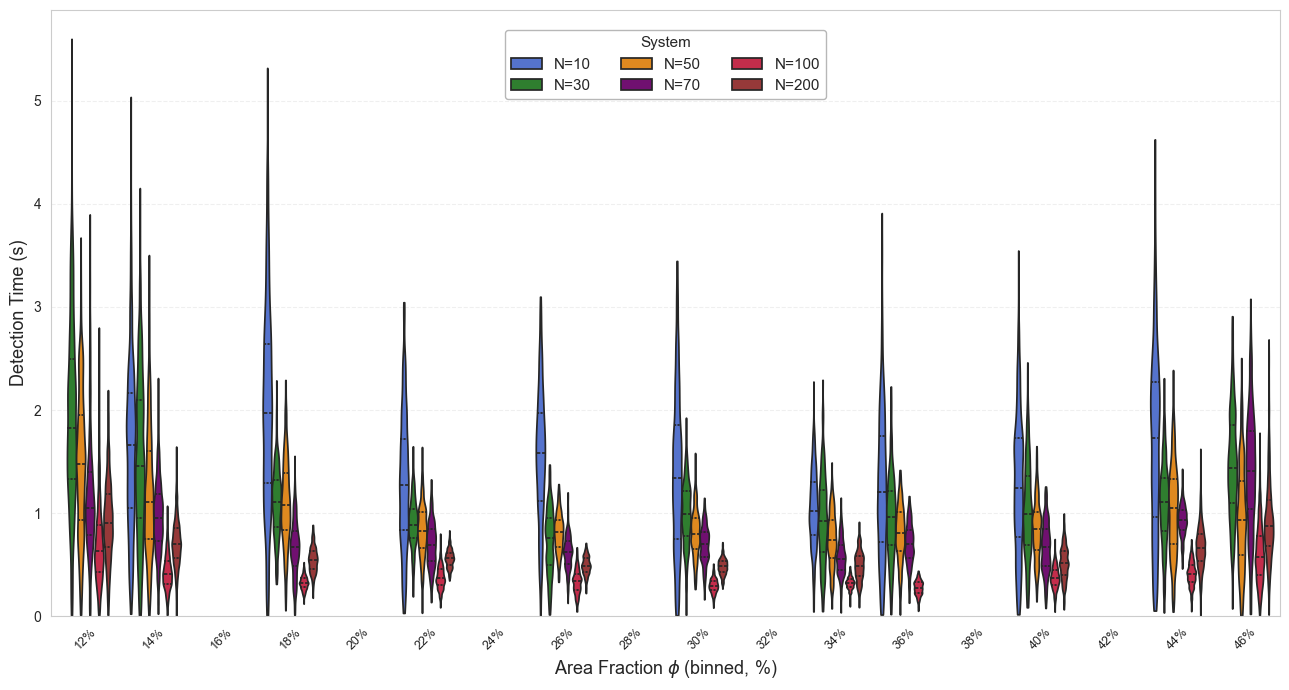

In [16]:
# FIGURE D — VIOLIN PLOTS: side-by-side overlay
figD, ax_vov = plt.subplots(figsize=(13, 7))
sns.set_style("whitegrid")

import pandas as pd

rows = []
for name, sys in systems.items():
    Np_arr  = sys["Np"]
    N_total = sys["N_total"]
    L       = sys["L"]
    for i, (n, dist) in enumerate(zip(Np_arr, sys["violin"])):
        phi_label = f"{np_to_phi(n, N_total, L)*100:.1f}%"
        for val in dist:
            rows.append({
                "System"        : name,
                "phi_label"     : phi_label,
                "phi_val"       : np_to_phi(n, N_total, L) * 100,
                "Detection Time": val,
            })

df = pd.DataFrame(rows)

# Bin phi into shared brackets for overlay comparison
phi_bins   = np.arange(12, 50, 2)
df["phi_bin"] = pd.cut(df["phi_val"], bins=phi_bins,
                        labels=[f"{b:.0f}%" for b in phi_bins[:-1]])
df = df.dropna(subset=["phi_bin"])

# Dynamic palette extracted directly from systems dictionary to guarantee exact match
palette_dict = {name: sys["color"] for name, sys in systems.items()}

sns.violinplot(
    data=df,
    x="phi_bin", y="Detection Time",
    hue="System",
    palette=palette_dict,         # <-- Dynamic color mapping matching the ergodic plot
    inner="quartile",
    cut=0,
    bw_adjust=0.6,
    ax=ax_vov,
    dodge=True,
    density_norm="width"
)

ax_vov.set_xlabel(r"Area Fraction $\phi$ (binned, %)", fontsize=13)
ax_vov.set_ylabel("Detection Time (s)", fontsize=13)

# ==========================================
# CENTERED 3x2 LEGEND SETUP
# ==========================================
ax_vov.legend(
    title="System", 
    title_fontsize=11, 
    fontsize=11,
    ncols=3,                      # 3 columns x 2 rows format
    loc='upper center', 
    bbox_to_anchor=(0.5, 0.98),  # Positioned top-center to eliminate dead space
    framealpha=0.95,
    edgecolor='0.7'
)

ax_vov.grid(True, axis='y', linestyle='--', alpha=0.3)
ax_vov.set_axisbelow(True)
ax_vov.set_ylim(bottom=0)
plt.xticks(rotation=45, fontsize=9)

plt.tight_layout()
plt.savefig("FigD_violin_overlay.jpg", dpi=300, bbox_inches='tight')
# plt.savefig("FigD_violin_overlay.pdf", dpi=300, bbox_inches='tight')
plt.show()